## GROUP 5 DATASET INSPECTION AND BASIC YOLO FORMAT CONVERSION

## About dataset

## Download

The data can be downloaded from the Labeled Information Library of Alexandria.

## Annotation Format

We follow the MOT annotation format, which is a CSV with the following columns:

| frame_number | object_id | x | y | w | h | class | species | occlusion | noise |
|--------------|-----------|---|---|---|---|-------|---------|-----------|-------|

- **class:** 0 if animals, 1 if humans

- **species:** between -1 and 8 representing species below; 3 and 4 occur only in real data; 5, 6, 7, 8 occur only in synthetic data (note: most very small objects have unknown species)

| Species ID | Species |
|------------|---------|
| -1 | unknown |
| 0 | human |
| 1 | elephant |
| 2 | lion |
| 3 | giraffe |
| 4 | dog |
| 5 | crocodile |
| 6 | hippo |
| 7 | zebra |
| 8 | rhino |

- **occlusion:** 0 if there is no occlusion, 1 if there is an occlusion (i.e., either occluding or occluded) (note: intersection over union threshold of 0.3 used to assign occlusion; more details in paper)

- **noise:** 0 if there is no noise, 1 if there is noise (note: noise labels were interpolated from object locations in previous and next frames; for more than 4 consecutive frames without labels, no noise labels were included; more details in paper)

## Terms of Use

This dataset is released under the Community Data License Agreement (permissive variant).

## Citing BIRDSAI

If you use this dataset, please consider citing our paper.

In [41]:
# 📘 Dataset Inspection Notebook
# Week 1 Evidence: TrainReal + Tracking Visualization

# --- Setup ---
import os
import cv2
import pandas as pd
import matplotlib.pyplot as plt

# Paths
base_path = r"C:\Users\nasee\Downloads\TrainReal\TrainReal"
img_root = os.path.join(base_path, "images")
ann_root = os.path.join(base_path, "annotations")
tracking_root = os.path.join(base_path, "tracking", "data_split_full")

print("Base path:", base_path)


Base path: C:\Users\nasee\Downloads\TrainReal\TrainReal


Using annotation file: C:\Users\nasee\Downloads\TrainReal\TrainReal\annotations\0000000367_0000000000.csv


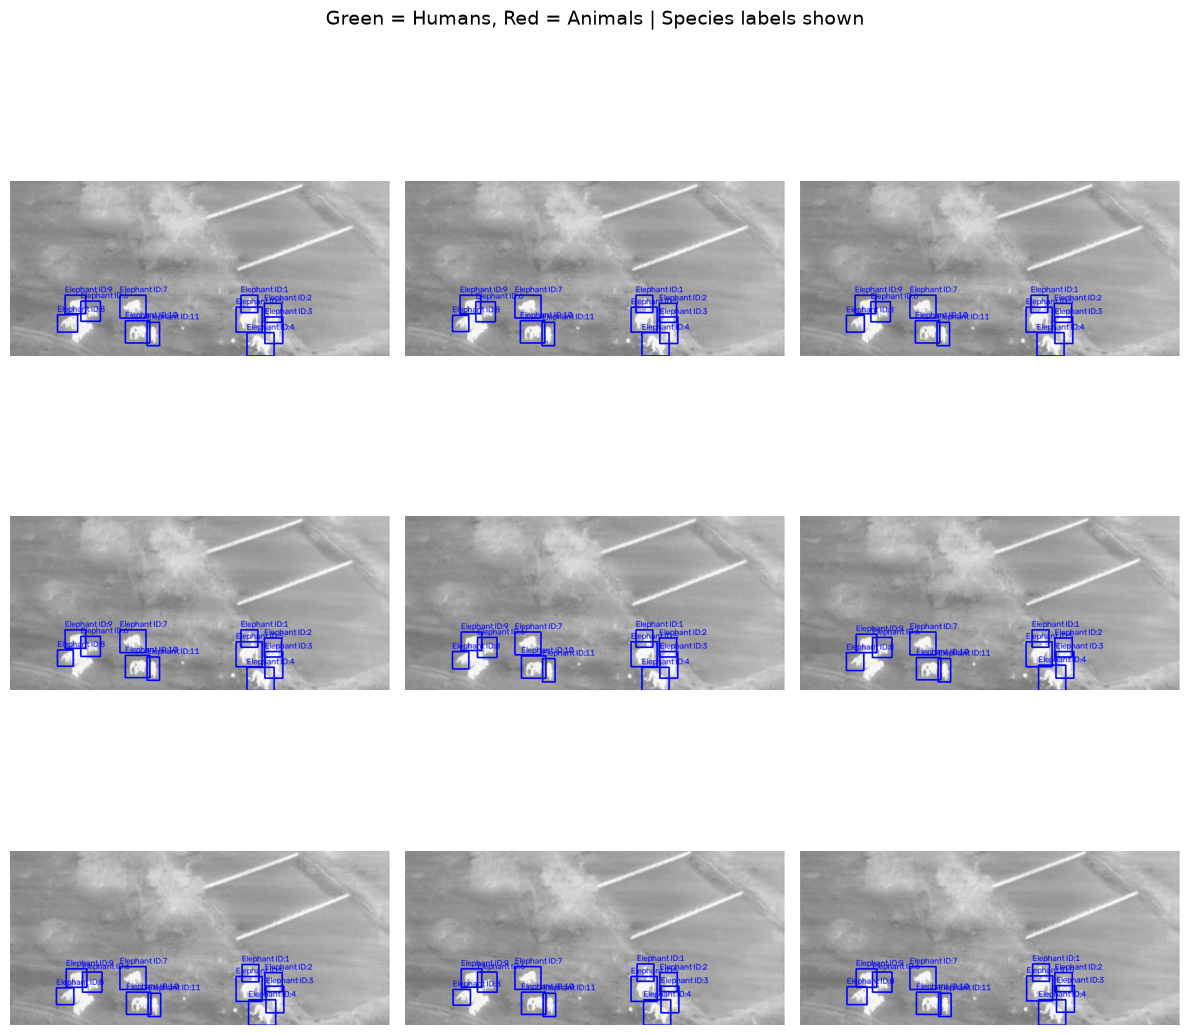

In [ ]:
# --- TrainReal Visualization ---
import cv2
import pandas as pd
import os
import matplotlib.pyplot as plt

# Species mapping from BIRDSAI documentation
species_map = {
    -1: "Unknown",
     0: "Human",
     1: "Elephant",
     2: "Lion",
     3: "Giraffe",
     4: "Dog",
     5: "Crocodile",
     6: "Hippo",
     7: "Zebra",
     8: "Rhino"
}

def visualize_trainreal(subseq_id="0000000367_0000000000"):
    img_folder = os.path.join(img_root, subseq_id)
    ann_file = os.path.join(ann_root, f"{subseq_id}.csv")

    print("Using annotation file:", ann_file)

    # Load CSV annotation
    df = pd.read_csv(ann_file, header=None,
                     names=["frame_id","object_id","x","y","w","h","cls","species","occluded","noisy"])

    frames = sorted(os.listdir(img_folder))[:9]
    images = []

    for fname in frames:
        frame_id = int(fname.split("_")[-1].split(".")[0])
        img_path = os.path.join(img_folder, fname)
        img = cv2.imread(img_path)

        boxes = df[df["frame_id"] == frame_id]
        for _, row in boxes.iterrows():
            x, y, w, h = int(row.x), int(row.y), int(row.w), int(row.h)

            # Color coding: humans green, animals red
            if row.cls == 1:   # human
                color = (0, 255, 0)
            else:              # animal
                color = (255, 0, 0)

            # Label with species name if available
            species_name = species_map.get(row.species, f"Species {row.species}")
            label = f"{species_name} ID:{row.object_id}"

            cv2.rectangle(img, (x, y), (x + w, y + h), color, 2)
            cv2.putText(img, label, (x, y - 5),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.5, color, 1)

        images.append(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))

    fig, axes = plt.subplots(3, 3, figsize=(12, 12))
    for ax, im in zip(axes.flatten(), images):
        ax.imshow(im)
        ax.axis("off")

    fig.suptitle("Green = Humans, Blue = Animals | Species labels shown", fontsize=14, color="black")
    plt.tight_layout()
    plt.show()

# Run demo
visualize_trainreal("0000000367_0000000000")


In [45]:
# --- Class Count Across All Sequences ---
import pandas as pd
import os

def count_classes(ann_root):
    counts = {"human": 0, "animal": 0}
    species_counts = {}

    for ann_file in os.listdir(ann_root):
        if ann_file.endswith(".csv"):
            df = pd.read_csv(os.path.join(ann_root, ann_file), header=None,
                             names=["frame_id","object_id","x","y","w","h","cls","species","occluded","noisy"])
            
            # Broad class counts
            counts["human"] += (df["cls"] == 1).sum()
            counts["animal"] += (df["cls"] == 0).sum()

            # Species counts
            for sp, c in df["species"].value_counts().items():
                species_counts[sp] = species_counts.get(sp, 0) + c

    return counts, species_counts

# Example usage
class_counts, species_counts = count_classes(ann_root)
print("Class counts across dataset:", class_counts)
print("Species counts across dataset:", species_counts)


Class counts across dataset: {'human': np.int64(12531), 'animal': np.int64(74668)}
Species counts across dataset: {1: 42973, -1: 20692, 3: 9979, 0: 12531, 2: 1024}


In [46]:
# --- Convert one annotation row to YOLO format ---
def convert_to_yolo(row, img_width, img_height):
    # Use species as the YOLO class ID (more detailed than just cls)
    yolo_class = row.species  

    # Handle unknown species (-1) by mapping to a special class or skipping
    if yolo_class == -1:
        return None  # skip unlabeled objects

    # Normalize coordinates
    x_center = (row.x + row.w / 2) / img_width
    y_center = (row.y + row.h / 2) / img_height
    w_norm = row.w / img_width
    h_norm = row.h / img_height

    return f"{yolo_class} {x_center:.6f} {y_center:.6f} {w_norm:.6f} {h_norm:.6f}"
ann_file = os.path.join(ann_root, "0000000367_0000000000.csv")
df = pd.read_csv(ann_file, header=None,
                 names=["frame_id","object_id","x","y","w","h","cls","species","occluded","noisy"])

img_folder = os.path.join(img_root, "0000000367_0000000000")
sample_img = cv2.imread(os.path.join(img_folder, sorted(os.listdir(img_folder))[0]))
h, w, _ = sample_img.shape

row = df.iloc[0]
print("Original row:", row.to_dict())
yolo_line = convert_to_yolo(row, w, h)
if yolo_line:
    print("YOLO format:", yolo_line)
else:
    print("Skipped: species unknown (-1)")


Original row: {'frame_id': 0, 'object_id': 1, 'x': 425, 'y': 209, 'w': 31, 'h': 32, 'cls': 0, 'species': 1, 'occluded': 0, 'noisy': 0}
YOLO format: 1 0.629286 0.700935 0.044286 0.099688


In [47]:
# --- Per-sequence summary ---
import pandas as pd
import os

def sequence_summary(ann_root):
    summary = []
    for ann_file in os.listdir(ann_root):
        if ann_file.endswith(".csv"):
            df = pd.read_csv(os.path.join(ann_root, ann_file), header=None,
                             names=["frame_id","object_id","x","y","w","h","cls","species","occluded","noisy"])
            
            # Correct mapping: cls=1 human, cls=0 animal
            humans = (df["cls"] == 1).sum()
            animals = (df["cls"] == 0).sum()
            
            summary.append({
                "sequence": ann_file.replace(".csv",""),
                "humans": humans,
                "animals": animals
            })
    return pd.DataFrame(summary)

# Example usage
summary_df = sequence_summary(ann_root)
print(summary_df.head())


                sequence  humans  animals
0  0000000010_0000000000       0      684
1  0000000054_0000000000       0      234
2  0000000056_0000000000       0      133
3  0000000062_0000000000       0     5148
4  0000000067_0000000005       0      195


In [48]:
def sequence_species_summary(ann_root):
    summary = []
    for ann_file in os.listdir(ann_root):
        if ann_file.endswith(".csv"):
            df = pd.read_csv(os.path.join(ann_root, ann_file), header=None,
                             names=["frame_id","object_id","x","y","w","h","cls","species","occluded","noisy"])
            
            species_counts = df["species"].value_counts().to_dict()
            summary.append({
                "sequence": ann_file.replace(".csv",""),
                **species_counts
            })
    return pd.DataFrame(summary).fillna(0)

species_summary_df = sequence_species_summary(ann_root)
print(species_summary_df.head())


                sequence      1      -1    3    0    2
0  0000000010_0000000000  684.0     0.0  0.0  0.0  0.0
1  0000000054_0000000000  234.0     0.0  0.0  0.0  0.0
2  0000000056_0000000000  133.0     0.0  0.0  0.0  0.0
3  0000000062_0000000000    0.0  5148.0  0.0  0.0  0.0
4  0000000067_0000000005    0.0   195.0  0.0  0.0  0.0
